# 3. Modal damping: T60 and quality factor Q

A stone "sounds like a bell" when its vibration modes **take long to die away**. This notebook measures how long each
mode lasts after the strike and expresses it as a modal reverberation time (T60) and a quality factor (Q). It tests
the hypothesis *the sound is dominated by a few lightly damped global modes, and their Q does not depend on the struck
zone*.

It uses the strikes of the **characterisation set** (notebook 01, section 1.3).

**Inputs:** the WAV files and `intermediate/strikes.csv` (notebook 01). **Outputs:** `tables/t03_damping_strikes.csv`,
`tables/t03_damping_modes.csv`, `tables/t03_damping_zone_mode.csv`, `tables/t03_mode_catalogue.csv`, figures `fig03*`.

## 3.1 Definitions

A free mode decays as $A(t) = A_0\,e^{-t/\tau}$. In decibels the envelope falls along a straight line with slope
$m$ (dB/s), and:

$$T_{60} = -\frac{60}{m}, \qquad \tau = \frac{T_{60}}{\ln 1000} = \frac{T_{60}}{6.91}, \qquad Q = \pi f \tau, \qquad \eta = \frac{1}{Q}$$

$T_{60}$ is the time the mode takes to fall by 60 dB; $Q$ compares that time with the period of oscillation (a Q of
1000 means that the mode oscillates about 1000/π ≈ 320 times before losing 96 % of its amplitude); $\eta$ is the loss
factor of the material and of the mounting (support, radiation).

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))   # folder with config.py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import config as C
warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.4})
pd.set_option("display.precision", 2)

from scipy import signal, stats
from scipy.io import wavfile
import seaborn as sns
warnings.filterwarnings("ignore", category=wavfile.WavFileWarning)
FS = C.FS

## 3.2 Long windows: from each strike to the next

The 0.4 s segments of notebook 01 are too short: a mode with T60 = 2 s falls by only 12 dB in 0.4 s, and a fit over
that interval **underestimates** Q. Here each strike is taken from its peak **to the start of the next strike** in the
recording.

The start of each strike is detected in the band above 4 kHz, where the contact of the hammer is strong and the
resonance of the stone no longer contributes, so that the tail of a mode is not mistaken for a new strike.

In [2]:
strikes = pd.read_csv(C.INTERMEDIATE / "strikes.csv").rename(columns={"i_peak": "i"})
strikes = strikes[strikes.set == "characterisation"].reset_index(drop=True)   # characterisation set
b_hp, a_hp = signal.butter(C.FILTER_ORDER, C.HIGHPASS_HZ / (0.5 * FS), btype="high")   # 300 Hz
b_hf, a_hf = signal.butter(4, 4000 / (0.5 * FS), btype="high")
sig, onsets = {}, {}
for w in strikes.file.unique():
    _, x = wavfile.read(C.AUDIO / w)
    xf = signal.filtfilt(b_hp, a_hp, x.astype(np.float32).mean(axis=1))
    env = signal.convolve(np.abs(signal.filtfilt(b_hf, a_hf, xf)), np.ones(96) / 96, "same")   # 2 ms
    pk, _ = signal.find_peaks(env, height=15 * 1.4826 * np.median(env), distance=int(0.15 * FS))
    sig[w], onsets[w] = xf, pk

def free_window(r):
    o = onsets[r.file]; nxt = o[o > r.i + int(0.1 * FS)]
    return ((nxt[0] if len(nxt) else len(sig[r.file])) - r.i) / FS - 0.02
strikes["window_s"] = strikes.apply(free_window, axis=1).clip(upper=2.0)
print(f"{len(strikes)} strikes; median free window = {strikes.window_s.median():.2f} s "
      f"(10th percentile: {strikes.window_s.quantile(.1):.2f} s)")

371 strikes; median free window = 1.21 s (10th percentile: 1.05 s)


## 3.3 Catalogue of global modes

The normalised spectra of all strikes of the characterisation set are averaged (free window, Hann, zero padding to
2¹⁸ points: interpolated resolution 0.18 Hz). Peaks between 300 and 3000 Hz with a prominence ≥ 3 % of the maximum
and at least 15 Hz apart are candidates; the catalogue keeps those with at least 20 accepted decay fits (section 3.6).
These are the frequencies the stone repeats wherever it is struck.

> The whole analysis uses a high-pass filter at `C.HIGHPASS_HZ` = 300 Hz: it keeps the lowest mode, at 384.9 Hz, and
> removes the wind noise that dominates the spectrum below 300 Hz.

Candidate global modes (Hz): [np.float64(321.4), np.float64(384.9), np.float64(599.5), np.float64(759.2), np.float64(848.9), np.float64(969.5), np.float64(1259.9), np.float64(1298.6), np.float64(1348.8), np.float64(1389.2), np.float64(1645.2), np.float64(1819.5), np.float64(1893.3), np.float64(1938.0)]
Candidate peaks (Hz, magnitude): [(np.float64(384.9), np.float32(0.511)), (np.float64(599.5), np.float32(0.49)), (np.float64(848.9), np.float32(0.46)), (np.float64(759.2), np.float32(0.341)), (np.float64(969.5), np.float32(0.3)), (np.float64(1348.8), np.float32(0.212)), (np.float64(321.4), np.float32(0.199)), (np.float64(1259.9), np.float32(0.107)), (np.float64(1645.2), np.float32(0.098)), (np.float64(1893.3), np.float32(0.075)), (np.float64(1389.2), np.float32(0.064)), (np.float64(1938.0), np.float32(0.054)), (np.float64(1819.5), np.float32(0.052)), (np.float64(1298.6), np.float32(0.047))]


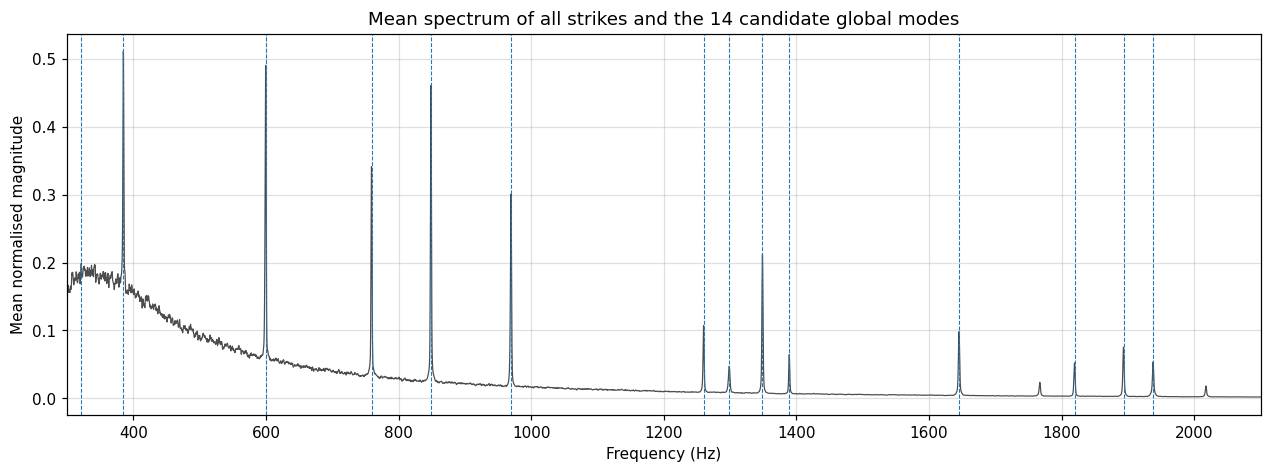

In [3]:
N_MODES = 14   # candidates; the final catalogue requires ≥ 20 valid decay fits (section 3.6)
N = 2 ** 18
f = np.fft.rfftfreq(N, 1 / FS)
band = (f > C.HIGHPASS_HZ) & (f < 3000)
spectra = {}
for k, r in strikes.iterrows():
    L = int(r.window_s * FS); s = sig[r.file][r.i:r.i + L]
    X = np.abs(np.fft.rfft(s * np.hanning(L), N)); spectra[k] = (X / X[band].max()).astype(np.float32)
mean = np.mean(list(spectra.values()), axis=0)
pk, _ = signal.find_peaks(mean[band], prominence=0.03, distance=int(15 / (f[1] - f[0])))
cand = sorted(zip(f[band][pk], mean[band][pk]), key=lambda z: -z[1])[:N_MODES]
MODES = sorted(round(c[0], 1) for c in cand)
print("Candidate global modes (Hz):", MODES)
print("Candidate peaks (Hz, magnitude):", [(round(a, 1), round(b, 3)) for a, b in sorted(zip(f[band][pk], mean[band][pk]), key=lambda z: -z[1])[:16]])
plt.figure(figsize=(14, 4.5))
plt.plot(f[band], mean[band], lw=.8, color="0.3")
for m in MODES:
    plt.axvline(m, color="C0", ls="--", lw=.7)
plt.xlabel("Frequency (Hz)"); plt.ylabel("Mean normalised magnitude"); plt.xlim(C.HIGHPASS_HZ, 2100)
plt.title(f"Mean spectrum of all strikes and the {len(MODES)} candidate global modes")
plt.savefig(C.FIGURES / "fig03a_global_modes.png", dpi=150, bbox_inches="tight"); plt.show()

## 3.4 Decay of each mode in each strike

For each strike and mode:

1. **Is it present?** The exact frequency is the spectral maximum within ±6 Hz of the global mode. It is measured
   only if its amplitude is ≥ 10 % of the strike maximum and it stands out ≥ 6 times (15.6 dB) above the surrounding
   spectrum (±40 Hz). Modes masked by broadband noise are thus discarded.
2. **Band-pass filter** of ±15 Hz around the frequency (Butterworth, zero phase). Its own response time (~10 ms) is
   negligible compared with the measured T60.
3. **Envelope** by Hilbert transform, smoothed over 5 ms, in dB relative to its maximum.
4. **Fit interval:** from 50 ms after the maximum (the transient of the hammer contact is discarded) until the
   envelope falls to −30 dB or to 8 dB above the noise floor of that band (measured just before the strike), or the
   end of the window.
5. **Least-squares line** → slope → T60 and Q. Accepted if it spans ≥ 10 dB of decay with R² ≥ 0.9.
6. **Cross-check:** the same interval is backward-integrated (Schroeder method) and its T60 compared.

When T60 is longer than the window, the value is **extrapolated** from the observed decay (10–27 dB), as for the
*early decay time* in room acoustics.

In [4]:
def measure(r, k, f0):
    L = int(r.window_s * FS); seg = sig[r.file][r.i:r.i + L]
    prev = sig[r.file][max(0, r.i - int(0.17 * FS)):r.i - int(0.02 * FS)]
    X = spectra[k] * 1.0
    s = (f > f0 - 6) & (f < f0 + 6); j = np.argmax(X[s]); fr = f[s][j]; amp = X[s][j]
    nb_ = (f > fr - 40) & (f < fr + 40) & (np.abs(f - fr) > 5); prom = X[s][j] / np.median(X[nb_])
    if amp < 0.10 or prom < 6:
        return None
    sos = signal.butter(2, [fr - 15, fr + 15], "bandpass", fs=FS, output="sos")
    y = signal.sosfiltfilt(sos, seg)
    env = signal.convolve(np.abs(signal.hilbert(y)), np.ones(240) / 240, "same")
    t = np.arange(len(env)) / FS
    imax = int(0.02 * FS) + np.argmax(env[int(0.02 * FS):int(0.15 * FS)])
    e = 20 * np.log10(env / env[imax] + 1e-12)
    yp = signal.sosfiltfilt(sos, prev) if len(prev) > 100 else None
    floor = 20 * np.log10(np.sqrt(2 * np.mean(yp ** 2)) / env[imax] + 1e-12) if yp is not None else -60
    lim = max(-30, floor + 8)
    low = np.where(e[imax:] < lim)[0]
    i_end = imax + (low[0] if len(low) else len(e) - imax - int(0.03 * FS))
    e3 = np.where(e[imax:] < -3)[0]
    i_start = max(imax + (e3[0] if len(e3) else 0), imax + int(0.05 * FS))
    if i_end - i_start < 100:
        return None
    tt, ee = t[i_start:i_end], e[i_start:i_end]
    p = np.polyfit(tt, ee, 1); r2 = 1 - np.var(ee - np.polyval(p, tt)) / np.var(ee)
    en = y[imax:i_end] ** 2; sch = 10 * np.log10(np.cumsum(en[::-1])[::-1] / en.sum() + 1e-15)
    span = -(e[i_end] - e[i_start]); ts = np.arange(len(sch)) / FS
    sel = (sch <= -3) & (sch >= -min(20, span - 2))
    m_sch = np.polyfit(ts[sel], sch[sel], 1)[0] if sel.sum() > 50 else np.nan
    T60 = -60 / p[0] if p[0] < 0 else np.nan
    return {"zone": r.zone, "strike": r.strike, "mode": f0, "f": fr, "amp": amp, "prominence": prom,
            "T60": T60, "T60_schroeder": -60 / m_sch if m_sch < 0 else np.nan, "Q": np.pi * fr * T60 / np.log(1000),
            "r2": r2, "decay_dB": span, "floor_dB": floor, "window_s": r.window_s}

fits = pd.DataFrame([m for k, r in strikes.iterrows() for f0 in MODES if (m := measure(r, k, f0)) is not None])
fits["valid"] = (fits.r2 >= 0.9) & (fits.decay_dB >= 10)
fits.to_csv(C.TABLES / "t03_damping_strikes.csv", index=False)
v = fits[fits.valid]
print(f"{len(fits)} measurements (strike × mode present); valid: {len(v)} ({len(v)/len(fits):.0%})")
print(f"Fitted decay: median {v.decay_dB.median():.0f} dB; median R² {v.r2.median():.3f}")
ratio = v.T60_schroeder / v.T60
print(f"Schroeder / Hilbert: median {ratio.median():.2f} (10th–90th percentiles: {ratio.quantile(.1):.2f}–{ratio.quantile(.9):.2f})")

1641 measurements (strike × mode present); valid: 1102 (67%)
Fitted decay: median 23 dB; median R² 0.988
Schroeder / Hilbert: median 0.94 (10th–90th percentiles: 0.83–1.00)


## 3.5 Example: decay of the modes in one strike
Envelopes (dB) of the modes measured in the first strike of zone 1 in the characterisation set, with the fitted lines.

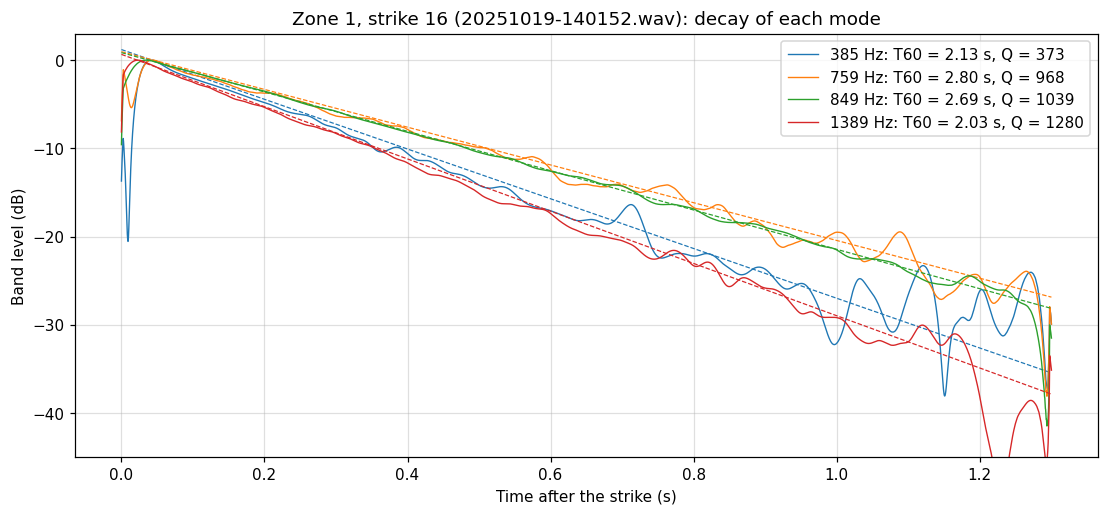

In [5]:
h1 = strikes[strikes.zone == 1].strike.min()
r = strikes[(strikes.zone == 1) & (strikes.strike == h1)].iloc[0]
L = int(r.window_s * FS); seg = sig[r.file][r.i:r.i + L]; t = np.arange(L) / FS
plt.figure(figsize=(12, 5))
for _, m in v[(v.zone == 1) & (v.strike == h1)].iterrows():
    sos = signal.butter(2, [m.f - 15, m.f + 15], "bandpass", fs=FS, output="sos")
    env = signal.convolve(np.abs(signal.hilbert(signal.sosfiltfilt(sos, seg))), np.ones(240) / 240, "same")
    e = 20 * np.log10(env / env[int(0.02 * FS):int(0.15 * FS)].max() + 1e-12)
    l, = plt.plot(t, e, lw=.9, label=f"{m.f:.0f} Hz: T60 = {m.T60:.2f} s, Q = {m.Q:.0f}")
    plt.plot(t, -60 * t / m.T60 + (e[int(0.05 * FS)] + 60 * 0.05 / m.T60), "--", color=l.get_color(), lw=.8)
plt.ylim(-45, 3); plt.xlabel("Time after the strike (s)"); plt.ylabel("Band level (dB)"); plt.legend()
plt.title(f"Zone 1, strike {h1} ({r.file}): decay of each mode")
plt.savefig(C.FIGURES / "fig03b_decay_example.png", dpi=150, bbox_inches="tight"); plt.show()

## 3.6 Q of each mode and its variation between zones

If Q is a property of the mode (of the whole stone), it must be the same wherever the stone is struck. For each mode
the median of each zone and the spread between zones (coefficient of variation) are computed. The few measurements
below a third of the median of the mode are flagged as outliers (decays dominated by noise).

In [6]:
v = v.copy()
v["outlier"] = v.Q < v.groupby("mode").Q.transform("median") / 3
print(f"Outliers excluded: {v.outlier.sum()} of {len(v)}")
vv = v[~v.outlier]
zm = vv.groupby(["mode", "zone"]).Q.median().reset_index()
tab = vv.groupby("mode").agg(f_Hz=("f", "median"), strikes=("Q", "size"), zones=("zone", "nunique"),
                             T60_s=("T60", "median"), Q=("Q", "median"),
                             Q_p25=("Q", lambda q: q.quantile(.25)), Q_p75=("Q", lambda q: q.quantile(.75)))
tab["eta_x1000"] = 1000 / tab.Q
tab["CV_between_zones"] = zm.groupby("mode").Q.agg(lambda q: q.std() / q.mean())
print("Candidates discarded (< 20 valid decay fits):", [m for m in MODES if m not in tab.index or tab.loc[m, "strikes"] < 20])
tab = tab[tab.strikes >= 20]
pd.DataFrame({"mode_Hz": tab.index}).to_csv(C.TABLES / "t03_mode_catalogue.csv", index=False)
zm = zm[zm["mode"].isin(tab.index)]; zm.to_csv(C.TABLES / "t03_damping_zone_mode.csv", index=False)
tab.to_csv(C.TABLES / "t03_damping_modes.csv")
tab.round({"f_Hz": 1, "T60_s": 2, "Q": 0, "Q_p25": 0, "Q_p75": 0, "eta_x1000": 2, "CV_between_zones": 2})

Outliers excluded: 12 of 1102
Candidates discarded (< 20 valid decay fits): [np.float64(321.4)]


,f_Hz,strikes,zones,T60_s,Q,Q_p25,Q_p75,eta_x1000,CV_between_zones
mode,,,,,,,,,
384.9,384.9,63,11,2.16,378.0,359.0,410.0,2.64,0.06
599.5,599.5,98,14,2.03,555.0,533.0,598.0,1.80,0.08
759.2,759.2,64,15,3.01,1038.0,985.0,1103.0,0.96,0.10
848.9,848.9,95,17,2.71,1047.0,1010.0,1082.0,0.96,0.09
969.5,969.5,163,15,1.65,729.0,694.0,785.0,1.37,0.07
1259.9,1259.9,58,8,1.88,1077.0,1033.0,1182.0,0.93,0.12
1298.6,1298.8,50,5,1.01,598.0,552.0,643.0,1.67,0.12
1348.8,1348.8,145,15,1.93,1186.0,1134.0,1256.0,0.84,0.09
1389.2,1389.2,47,7,1.96,1237.0,1204.0,1319.0,0.81,0.09


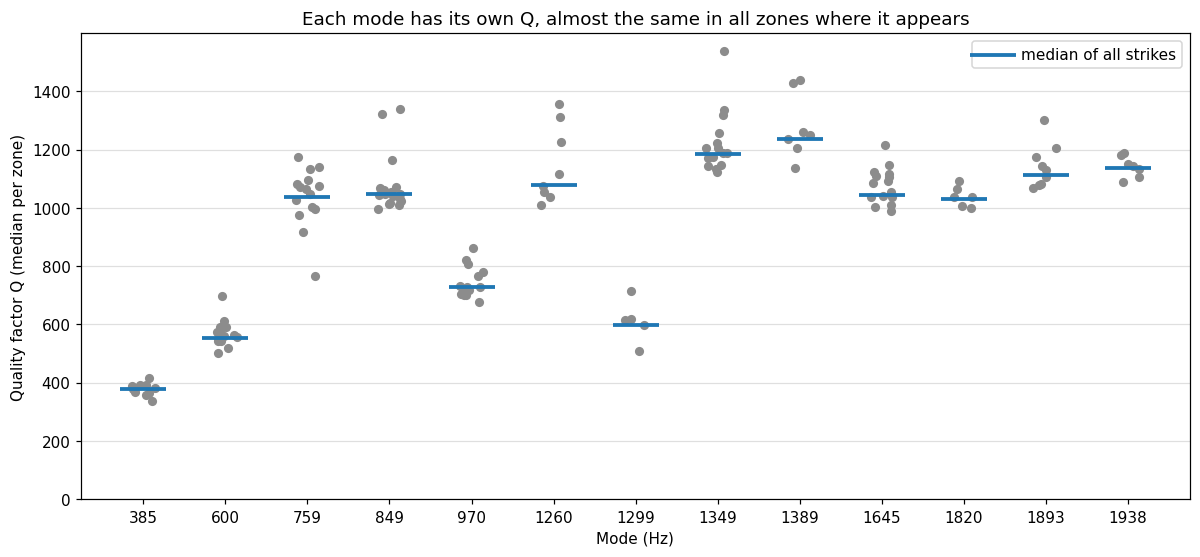

In [7]:
np.random.seed(C.SEED)   # fixed jitter of the points
fig, ax = plt.subplots(figsize=(13, 5.5))
order = list(tab.index)
sns.stripplot(x="mode", y="Q", data=zm, order=order, color="0.55", size=6, jitter=.15, ax=ax)
ax.scatter(range(len(order)), tab.Q, marker="_", s=900, color="C0", linewidths=2.5, zorder=3, label="median of all strikes")
ax.set_xticks(range(len(order))); ax.set_xticklabels([f"{m:.0f}" for m in order])
ax.set_xlabel("Mode (Hz)"); ax.set_ylabel("Quality factor Q (median per zone)"); ax.set_ylim(0, None); ax.legend()
ax.set_title("Each mode has its own Q, almost the same in all zones where it appears")
plt.savefig(C.FIGURES / "fig03c_Q_per_mode.png", dpi=150, bbox_inches="tight"); plt.show()

## 3.7 Does Q depend on frequency?

Spearman Q vs frequency (13 modes): rho = +0.63, p = 0.02


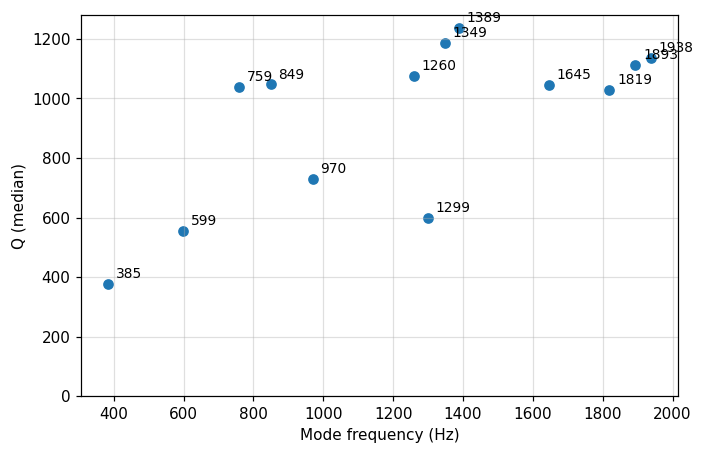

In [8]:
rho, p = stats.spearmanr(tab.f_Hz, tab.Q)
print(f"Spearman Q vs frequency ({len(tab)} modes): rho = {rho:+.2f}, p = {p:.2f}")
plt.figure(figsize=(7, 4.5)); plt.scatter(tab.f_Hz, tab.Q, color="C0")
for m, r in tab.iterrows():
    plt.annotate(f"{r.f_Hz:.0f}", (r.f_Hz, r.Q), textcoords="offset points", xytext=(5, 4), fontsize=9)
plt.xlabel("Mode frequency (Hz)"); plt.ylabel("Q (median)"); plt.ylim(0, None)
plt.savefig(C.FIGURES / "fig03d_Q_vs_frequency.png", dpi=150, bbox_inches="tight"); plt.show()

## Conclusion

With the strikes of the characterisation set:

* The modes of the stone are **lightly damped**: Q between 378 and 1237 (loss factor η ≈ 0.8–2.6 × 10⁻³) and T60 from
  1.0 to 3.0 s. The 759 and 849 Hz modes ring the longest (T60 ≈ 2.7–3.0 s).
* **Q is a property of each mode, not of the zone**: the coefficient of variation of the zone medians is 3–12 %. This
  supports the hypothesis of global modes and validates the method, since the same mode measured from different points
  gives the same damping.
* The lowest mode (385 Hz) is the most damped (Q ≈ 380), followed by the 599 and 1299 Hz modes (Q ≈ 555–600) and the
  970 Hz mode (Q ≈ 730). The other nine have Q ≈ 1030–1240. Across the 13 modes, Q increases with frequency (Spearman
  ρ = +0.63, p = 0.02), mainly because of the low modes.
* The two estimators (Hilbert envelope and Schroeder integration) agree within ~6 % (median ratio 0.94).
* Of the 14 candidate peaks of the mean spectrum, the one at 321 Hz has fewer than 20 valid decay fits and is left out
  of the catalogue.

**Limitations:** the microphone was in the air, so the measured Q includes radiation and support losses, not only those
of the material. T60 values longer than the window (≈1.2 s) are extrapolated from the first 10–27 dB of decay.